# Longer training: Expected SARSA, DQN, and Dyna-DQN

This repeats the original 300 m / 16 s comparison with **1,000 episodes per
agent instead of 60**. Networks, reward, action choices, learning rates, replay,
and Dyna planning settings stay fixed. Epsilon decreases over the longer run,
so this tests more training with a slower exploration schedule together.

We evaluate on 20 traffic seeds in each of clear, rain, and fog weather (60
trials per policy). The original four seeds are included, and a separate table
compares results on those same 12 scenarios. This is still one training seed.

Run top to bottom. Each trained policy is saved before the next one starts.
The learned Dyna prediction model is also saved for later diagnostic work.
These are evaluation artifacts, not complete training-resume checkpoints.

The sections below explain each part in plain language. The original short
experiment remains in `sensor_dqn_experiment.ipynb`.

The three agents can train concurrently using `experiments/run_long_dqn.py`.
When `FINAL_PROJECT_DQN_RUN_DIR` points to that prepared results folder, this
notebook loads completed policies and histories, checks matching settings, and
runs the same plots and evaluation. Without that variable, it trains sequentially.


## 1. Setup

DQN needs PyTorch to build the networks and calculate weight updates. It is an
optional dependency; the original SARSA notebooks still work without it.
Install once from the project root if needed:

```bash
.venv/bin/python -m pip install -r requirements-dqn.txt
```

The agents run on the CPU to keep this example straightforward.

In [1]:
from pathlib import Path
import sys, os, json
from dataclasses import asdict
from datetime import datetime
from zoneinfo import ZoneInfo
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "environments/sensor_highway/env.py").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook inside MORL4AVSO.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from environments.sensor_highway import ExperimentConfig
from algorithms.sensor_agent import AgentSettings, LinearExpectedSarsa
from algorithms.dqn_agent import DQNSettings, DQNAgent
from experiments.agent_helpers import train_agent, evaluate_agents
from experiments.dqn_helpers import train_dqn
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
# Small CPU networks avoid unnecessary multithreading overhead.
torch.set_num_threads(1)

Python: .venv/bin/python
PyTorch: 2.15.0


## 2. Reuse our observations, actions, and reward

`ObservationEncoder` makes the same small feature vector used by SARSA. It
summarizes nearby obstacle/free-space evidence, measurement confidence and age,
relative motion, ego telemetry, sensor status, and remaining route/time.
Unknown space is not treated as free road. No hidden traffic truth enters the networks.

There are **20 outputs**: five driving actions × four sensing modes (`off`,
`front`, `radar_rgb`, `all_on`). Each output is the Q estimate for one choice.
The network has one hidden layer of 64 units. A ReLU lets it learn relationships
that a single weighted sum cannot represent. It still loses details during encoding.

The reward matches the short-route SARSA notebook: progress earns reward, time
and sensing cost reward, a safe finish earns a bonus, and failures incur a penalty.
Keeping these settings fixed makes algorithm comparisons easier to interpret.

In [2]:
TRAIN_SEED = 42
TRAIN_EPISODES = 1000
TEST_SEEDS = list(range(100_000, 100_020))
TEST_WEATHER = ["clear", "rain", "fog"]

config = ExperimentConfig()
config.highway.update(duration=16, high_speed_reward=0.0, collision_reward=-10.0)
config.weather.preset = "random"
config.weather.severity = 0.7
config.reward.route_distance_m = 300
config.reward.progress_weight = 0.02
config.reward.time_weight = 0.1
config.reward.completion_bonus = 10.0
config.reward.early_completion_bonus = 5.0
config.reward.failure_penalty = 10.0
config.validate()

settings = DQNSettings(episodes=TRAIN_EPISODES)
sarsa_settings = AgentSettings(episodes=TRAIN_EPISODES, alpha=0.12, gamma=settings.gamma,
                              epsilon_start=settings.epsilon_start, epsilon_end=settings.epsilon_end)
assert not set(TEST_SEEDS).intersection(range(TRAIN_SEED, TRAIN_SEED + TRAIN_EPISODES))
display(pd.Series(asdict(settings), name="DQN settings"))

# Optionally load a completed run prepared by the parallel training runner.
# Without this environment variable, Run All starts a fresh training run.
existing_run = os.environ.get("FINAL_PROJECT_DQN_RUN_DIR")
if existing_run:
    output = Path(existing_run).resolve()
    saved = json.loads((output / "run_settings.json").read_text())
    assert saved["dqn_settings"] == asdict(settings), "Training settings differ"
    assert saved["sarsa_settings"] == asdict(sarsa_settings), "SARSA settings differ"
    assert saved["training_seed"] == TRAIN_SEED, "Training seed differs"
    assert asdict(ExperimentConfig.load(output / "config.json")) == asdict(config), "Environment differs"
else:
    stamp = datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S_%f")
    output = PROJECT_ROOT / "runs/comparisons" / f"dqn_long_training_{stamp}"
    output.mkdir(parents=True, exist_ok=False)
    config.save(output / "config.json")
    (output / "run_settings.json").write_text(json.dumps({
        "dqn_settings": asdict(settings), "sarsa_settings": asdict(sarsa_settings),
        "training_seed": TRAIN_SEED, "test_seeds": TEST_SEEDS, "test_weather": TEST_WEATHER,
        "status": "training", "torch_threads": torch.get_num_threads(),
    }, indent=2))
print("Results folder:", output)


episodes                  1000.000
learning_rate                0.001
gamma                        0.990
epsilon_start                1.000
epsilon_end                  0.100
hidden_size                 64.000
batch_size                  32.000
replay_capacity          10000.000
learning_starts             64.000
target_update_steps        100.000
planning_steps               2.000
model_learning_starts      200.000
Name: DQN settings, dtype: float64

Results folder: runs/comparisons/dqn_long_training_20261112_170403_004536


## 3. Understand the DQN parts

**Choosing an action (`select`).** With probability epsilon, choose randomly.
Otherwise, choose the highest Q value. Epsilon decreases from 1.0 to 0.1 during training.
This exploration rule is the same idea as our SARSA agent.

**Replay buffer (`ReplayBuffer`).** Save each real step as
`(features, action, reward, next_features, terminal)`. Randomly sample 32 stored
steps at a time. Mixing experience reduces dependence on consecutive road scenes.
Wait for 64 stored steps before starting Q updates. The buffer holds at most 10,000.

**Two Q networks (`online` and `target`).** The online network learns every update.
The target network supplies future-value estimates and is copied from the online
network every 100 Q updates. This makes the training target change less often.

**Learning target (`td_targets`).** SARSA averages future Q values under its
exploring policy. DQN instead uses the best estimated next action:

```text
SARSA: target = reward + gamma × [(1-epsilon) × max(Q_next) + epsilon × mean(Q_next)]
DQN:   target = reward + gamma × max(target_network(next_features))
```

A crash, off-road ending, route finish, or route deadline has `target = reward`.
For the original continuing-driving task, an artificial time cutoff still includes
future value, matching our existing SARSA convention.

**Weight update (`learn_batch`).** Select the online Q output for the action that
was taken, compare it with the target using Smooth L1 loss, and let Adam adjust
the weights. Smooth L1 reduces the influence of unusually large errors. Gradient
clipping limits the size of the gradient before the optimizer uses it.
These are standard DQN ingredients; see the
[official PyTorch DQN tutorial](https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html).
The code here uses ordinary DQN with periodic target copies.

In [3]:
if (output / "dqn_training_complete.json").exists():
    dqn_agent = DQNAgent.load(output / "dqn.pt")
    dqn_history = pd.read_csv(output / "dqn_training.csv")
    print("Loaded completed DQN training.")
else:
    dqn_agent, dqn_history = train_dqn(config, settings, seed=TRAIN_SEED)
    dqn_agent.save(output / "dqn.pt")
    dqn_history.to_csv(output / "dqn_training.csv", index=False)
print(dqn_agent.online)
display(dqn_history.tail())

Loaded completed DQN training.
Sequential(
  (0): Linear(in_features=112, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=20, bias=True)
)


,episode,seed,epsilon,return,energy_j,steps,crashed,route_completed,elapsed_s,distance_m,q_updates,q_loss,model_loss,planning_loss
995,996,1037,0.103604,12.688103,926.55,29,False,True,14.5,306.954037,19801,0.478730,NaN,NaN
996,997,1038,0.102703,-18.808588,156.35,12,True,False,6.0,126.912511,19813,0.735510,NaN,NaN
997,998,1039,0.101802,14.342326,280.40,25,False,True,12.5,301.750078,19838,0.422214,NaN,NaN
998,999,1040,0.100901,13.075863,252.35,30,False,True,15.0,305.194146,19868,0.590621,NaN,NaN
999,1000,1041,0.100000,13.057087,283.40,30,False,True,15.0,304.917038,19898,0.565688,NaN,NaN


## 4. Add the Dyna offshoot

Dyna adds a second way to practice: predict what might happen, then learn from
that prediction. **Replay alone is not Dyna**: replay repeats actual experience;
Dyna uses a model to produce outcomes that were not directly observed.

**Prediction model (`model_predictions`).** Input the current features and action.
The action is represented by a vector with one entry set to 1. Output a predicted
feature change, reward, and probability that no future value should follow.
Predicting the change means the model learns what moved rather than rebuilding
the entire observation from scratch.

**Model learning (`learn_model`).** Compare predictions against real stored steps.
Use Smooth L1 for feature changes and rewards, and binary cross-entropy for the
terminal flag. Train the model once per real Q update. It never receives simulator
traffic truth.

**Planning (`imagine_batch`).** After 200 stored real steps, sample real starting
feature/action pairs and predict their outcomes. Keep features within [-1, 1] and
preserve the encoder's constant bias. Use the prediction to make two extra Q
updates per real step:

```text
imagined_target = predicted_reward
                 + gamma × (1 - predicted_terminal_probability)
                         × max(target_network(predicted_next_features))
```

We use the ending probability directly instead of forcing a yes/no decision.
Each prediction starts from real data and goes only one step ahead. Imagined
transitions are never stored in the real replay buffer, and Q updates do not
backpropagate into the prediction model.

This is a simple Dyna-style feature model. Predictions can be wrong, especially
for rare crashes or partially observed traffic. Clipping does not guarantee a
physically valid scene. Planning may hurt performance; it is a hypothesis to test.
Set `planning_steps=0` to disable imagined updates. Dyna uses more computation
than DQN at the same real episode budget.

In [4]:
if (output / "dyna_dqn_training_complete.json").exists():
    dyna_agent = DQNAgent.load(output / "dyna_dqn.pt")
    dyna_agent.model.load_state_dict(torch.load(output / "dyna_prediction_model.pt", weights_only=True))
    dyna_history = pd.read_csv(output / "dyna_dqn_training.csv")
    print("Loaded completed Dyna-DQN training.")
else:
    dyna_agent, dyna_history = train_dqn(config, settings, seed=TRAIN_SEED, dyna=True)
    dyna_agent.save(output / "dyna_dqn.pt")
    torch.save(dyna_agent.model.state_dict(), output / "dyna_prediction_model.pt")
    dyna_history.to_csv(output / "dyna_dqn_training.csv", index=False)
display(dyna_history.tail())

Loaded completed Dyna-DQN training.


,episode,seed,epsilon,return,energy_j,steps,crashed,route_completed,elapsed_s,distance_m,q_updates,q_loss,model_loss,planning_loss
995,996,1037,0.103604,-16.938552,117.55,21,True,False,10.5,263.671998,64096,0.344095,0.423260,0.102181
996,997,1038,0.102703,14.198775,157.95,26,False,True,13.0,306.951725,64174,0.541192,0.457476,0.105695
997,998,1039,0.101802,13.489447,365.05,28,False,True,14.0,305.188896,64258,0.500493,0.423960,0.107518
998,999,1040,0.100901,13.357913,491.75,28,False,True,14.0,306.837693,64342,0.471813,0.391946,0.116947
999,1000,1041,0.100000,12.797830,805.75,29,False,True,14.5,305.892509,64429,0.512956,0.519249,0.109302


## 5. Train a fresh Expected SARSA reference

Use the same reward, features, exploration schedule, episode count, and seed range.
The algorithms can choose different actions, so they collect different experience.
Equal episode counts also do not guarantee equal numbers of real steps because
crashes and early finishes change episode length. Compare `steps` as well.
The neural learning rate and SARSA alpha have different meanings.

Loaded completed SARSA training.


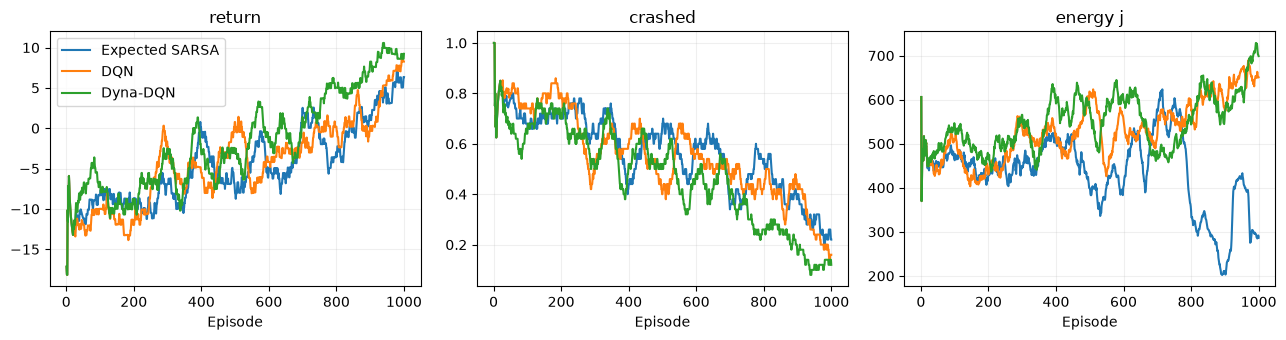

,real_steps
Expected SARSA,19580
DQN,19961
Dyna-DQN,21630


In [5]:
if (output / "sarsa_training_complete.json").exists():
    sarsa_agent = LinearExpectedSarsa.load(output / "sarsa.npz")
    sarsa_history = pd.read_csv(output / "sarsa_training.csv")
    print("Loaded completed SARSA training.")
else:
    sarsa_agent, sarsa_history = train_agent(config, sarsa_settings, seed=TRAIN_SEED)
    sarsa_agent.save(output / "sarsa.npz")
    sarsa_history.to_csv(output / "sarsa_training.csv", index=False)
histories = {"Expected SARSA": sarsa_history, "DQN": dqn_history, "Dyna-DQN": dyna_history}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for name, history in histories.items():
    for ax, metric in zip(axes, ["return", "crashed", "energy_j"]):
        ax.plot(history.episode, history[metric].astype(float).rolling(50, min_periods=1).mean(), label=name)
        ax.set(xlabel="Episode", title=metric.replace("_", " "))
        ax.grid(alpha=.2)
axes[0].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({name: {"real_steps": int(h.steps.sum())} for name, h in histories.items()}).T)

## 6. Evaluate without learning or exploration

The existing evaluator already works with all three agents: each supports
`select`, `decode`, and `feature_schema`. It calls no learning methods.
Use new traffic seeds in clear, rain, and fog conditions. Include the existing
fixed IDLE and random-driving baselines with all sensors on.

Read completion and crash fractions first, then successful completion time and
sensing power. An early crash can produce low total energy. Low training loss
only means the network fits its targets; it does not show good driving.
This run uses 1,000 episodes and 20 traffic seeds per weather condition.
Repeat training seeds before claiming that one algorithm is better.

Evaluated clear


Evaluated rain


Evaluated fog


,episodes,mean_return,crash_fraction,completion_fraction,successful_finish_time_s,mean_power_w,mean_distance_m
policy,,,,,,,
Expected SARSA,60,8.726,0.150,0.850,14.314,12.067,281.181
DQN,60,11.770,0.017,0.983,15.000,71.417,301.720
Dyna-DQN,60,11.368,0.033,0.967,14.759,75.434,303.382
idle_all_on,60,-5.829,0.600,0.400,12.000,123.000,232.910
random_all_on,60,-12.666,0.800,0.200,13.000,123.000,172.878


Long training, original 12 evaluation scenarios:


,episodes,mean_return,crash_fraction,completion_fraction,successful_finish_time_s,mean_power_w
policy,,,,,,
Expected SARSA,12,13.505,0.000,1.000,14.375,9.424
DQN,12,12.259,0.000,1.000,15.000,73.107
Dyna-DQN,12,9.884,0.083,0.917,14.727,74.312
idle_all_on,12,-10.416,0.750,0.250,12.000,123.000
random_all_on,12,-11.158,0.750,0.250,14.000,123.000


completion_fraction  crash_fraction  \
training_budget policy                                                
60 episodes     Expected SARSA                0.917           0.083   
                DQN                           0.250           0.750   
                Dyna-DQN                      0.500           0.500   
                idle_all_on                   0.250           0.750   
                random_all_on                 0.250           0.750   
1000 episodes   Expected SARSA                1.000           0.000   
                DQN                           1.000           0.000   
                Dyna-DQN                      0.917           0.083   
                idle_all_on                   0.250           0.750   
                random_all_on                 0.250           0.750   

                                mean_return  
training_budget policy                       
60 episodes     Expected SARSA       10.261  
                DQN                  -9.918  
                Dyna-DQN             -1.379  
                idle_all_on         -10.416  
                random_all_on       -11.158  
1000 episodes   Expected SARSA       13.505  
                DQN                  12.259  
                Dyna-DQN              9.884  
                idle_all_on         -10.416  
                random_all_on       -11.158

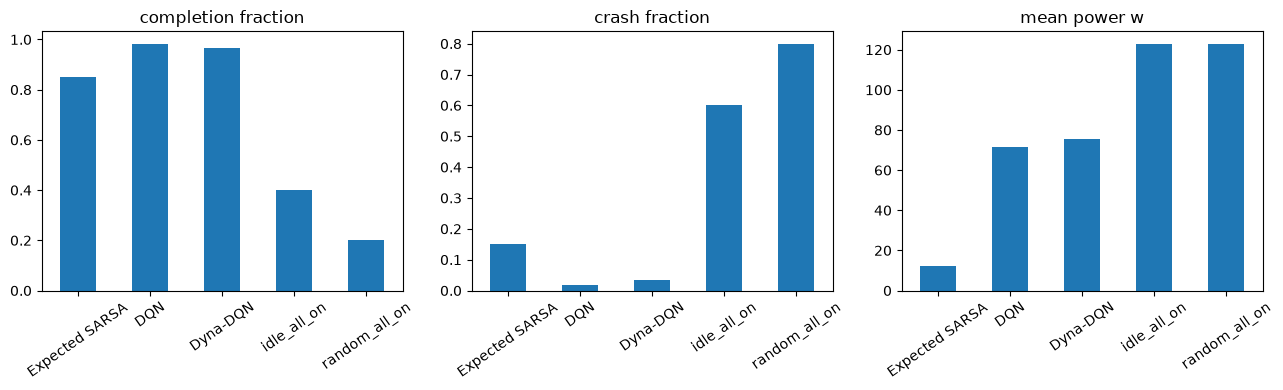

In [6]:
agents = {"Expected SARSA": sarsa_agent, "DQN": dqn_agent, "Dyna-DQN": dyna_agent,
          "idle_all_on": None, "random_all_on": None}
evaluation = evaluate_agents(config, agents, TEST_SEEDS, TEST_WEATHER)
summary = evaluation.groupby("policy", sort=False).agg(
    episodes=("seed", "count"), mean_return=("return", "mean"),
    crash_fraction=("crashed", "mean"), completion_fraction=("completed", "mean"),
    successful_finish_time_s=("completion_time_s", "mean"),
    mean_power_w=("mean_power_w", "mean"), mean_distance_m=("distance_m", "mean"))
display(summary.round(3))
evaluation.to_csv(output / "evaluation.csv", index=False)
summary.to_csv(output / "summary.csv")
original_scenarios = evaluation[evaluation.seed < 100_004]
matched_summary = original_scenarios.groupby("policy", sort=False).agg(
    episodes=("seed", "count"), mean_return=("return", "mean"),
    crash_fraction=("crashed", "mean"), completion_fraction=("completed", "mean"),
    successful_finish_time_s=("completion_time_s", "mean"),
    mean_power_w=("mean_power_w", "mean"))
matched_summary.to_csv(output / "original_scenarios_summary.csv")
print("Long training, original 12 evaluation scenarios:")
display(matched_summary.round(3))
old_path = PROJECT_ROOT / "runs/comparisons/dqn_comparison_20261112_125812_127055/summary.csv"
if old_path.exists():
    old_summary = pd.read_csv(old_path).set_index("policy")
    comparison = pd.concat({"60 episodes": old_summary, "1000 episodes": matched_summary}, names=["training_budget"])
    comparison.to_csv(output / "matched_budget_comparison.csv")
    display(comparison[["completion_fraction", "crash_fraction", "mean_return"]].round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric in zip(axes, ["completion_fraction", "crash_fraction", "mean_power_w"]):
    summary[metric].plot.bar(ax=ax, rot=35, title=metric.replace("_", " "))
    ax.set_xlabel("")
plt.tight_layout()
fig.savefig(output / "evaluation_summary.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Save models and matching settings

Save policies with their environment configuration, histories, and evaluation.
`DQNAgent.load` restores either neural policy for evaluation. It does **not**
restore the replay buffer, optimizer, target-update count, or learned dynamics
model, so this is not an exact training-resume checkpoint. Use the saved config
with its matching observation encoder. Each save creates a fresh directory.

In [7]:
SAVE_RUN = True
if SAVE_RUN:
    config.save(output / "config.json")
    dqn_agent.save(output / "dqn.pt")
    dyna_agent.save(output / "dyna_dqn.pt")
    sarsa_agent.save(output / "sarsa.npz")
    for name, history in [("dqn", dqn_history), ("dyna_dqn", dyna_history), ("sarsa", sarsa_history)]:
        history.to_csv(output / f"{name}_training.csv", index=False)
    evaluation.to_csv(output / "evaluation.csv", index=False)
    summary.to_csv(output / "summary.csv")
    (output / "metadata.json").write_text(json.dumps({
        "dqn_settings": asdict(settings), "sarsa_settings": asdict(sarsa_settings),
        "training_seed": TRAIN_SEED, "test_seeds": TEST_SEEDS, "test_weather": TEST_WEATHER,
        "feature_schema": dqn_agent.feature_schema, "actions": dqn_agent.actions,
        "torch": str(torch.__version__), "numpy": np.__version__, "python": sys.version,
        "checkpoint_purpose": "evaluation only",
    }, indent=2))
    restored = DQNAgent.load(output / "dyna_dqn.pt")
    for original, loaded in zip(dyna_agent.online.parameters(), restored.online.parameters()):
        assert torch.equal(original, loaded)
    print("Saved:", output)
    run_settings = json.loads((output / "run_settings.json").read_text())
    run_settings["status"] = "complete"
    (output / "run_settings.json").write_text(json.dumps(run_settings, indent=2))


Saved: runs/comparisons/dqn_long_training_20261112_170403_004536


## 8. A simple next experiment

Run DQN, then Dyna-DQN with `planning_steps` of 0, 1, and 2. Keep the task and real
interaction budget fixed and repeat several training seeds. Compare completion,
crashes, power, real steps, and total Q updates. If planning hurts, the learned
model may need better data or more time before it is used.

The shared encoder discards scene detail and the agents have no recurrent memory.
A deterministic one-step model cannot fully describe uncertain hidden traffic.
This example implements the algorithms; its performance must be measured.

## Recorded results from this run

Results folder: `runs/comparisons/dqn_long_training_20261112_170403_004536`.
These numbers describe the saved run; fresh training runs may differ.

| Agent | Completion across 60 scenarios | Crashes |
| --- | --- | --- |
| Expected SARSA | 51/60 (85.0%) | 9/60 |
| DQN | 59/60 (98.3%) | 1/60 |
| Dyna-DQN | 58/60 (96.7%) | 2/60 |

On the original 12 scenarios, DQN improved from **3/12 to 12/12** finishes,
and Dyna-DQN from **6/12 to 11/12**. SARSA improved from 11/12 to 12/12 there.
The expanded evaluation exposes failures that those four original traffic seeds miss.

Both neural policies now drive more slowly and keep sensors enabled for most
decisions. Dyna-DQN no longer chooses left/off on every decision. The results
support insufficient training as a contributor to the earlier failure, although
we also stretched the exploration schedule. They do not isolate the role of
sensing from slower driving, or establish that Dyna planning improves DQN.

See the results folder's `study_report.md` for power, action frequencies, real
steps, Q updates, and the matched short/long comparison. Only one training seed
was used, so repeat training seeds before claiming consistent superiority.
